In [1]:
import os
import glob
import numpy as np
np.random.seed(2345345)
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.image as mpimg

import re
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Automatically detect if running on Kaggle or Locally
IS_KAGGLE = os.path.exists('/kaggle/input')
BASE_DIR = '/kaggle/input/competitions/rogii-wellbore-geology-prediction' if IS_KAGGLE else '../data'

print(f"Running on {'Kaggle' if IS_KAGGLE else 'Local Environment'}")
print(f"Data Directory: {BASE_DIR}")
train_data = os.path.join(BASE_DIR, "train")
file_paths = sorted(os.listdir(train_data))

# Regex pattern: 
pattern = re.compile(r'([^/\\]+)__horizontal_well\.csv')

well_names = []
for path in file_paths:
    match = pattern.search(path)
    if match:
        well_names.append(match.group(1))

print("Extracted Well Names:")
print(len(well_names), "Well Names")

Running on Local Environment
Data Directory: ../data
Extracted Well Names:
773 Well Names


In [3]:
well = np.random.choice(well_names)

hw = pd.read_csv(train_data + f"/{well}__horizontal_well.csv")
tw = pd.read_csv(train_data + f"/{well}__typewell.csv")
pic = train_data + f"/{well}.png"

mask = hw['TVT_input'].isna()
evalz = hw[mask].copy()

well, hw.shape, tw.shape, evalz.shape

(np.str_('521a7819'), (7224, 13), (2087, 3), (5200, 13))

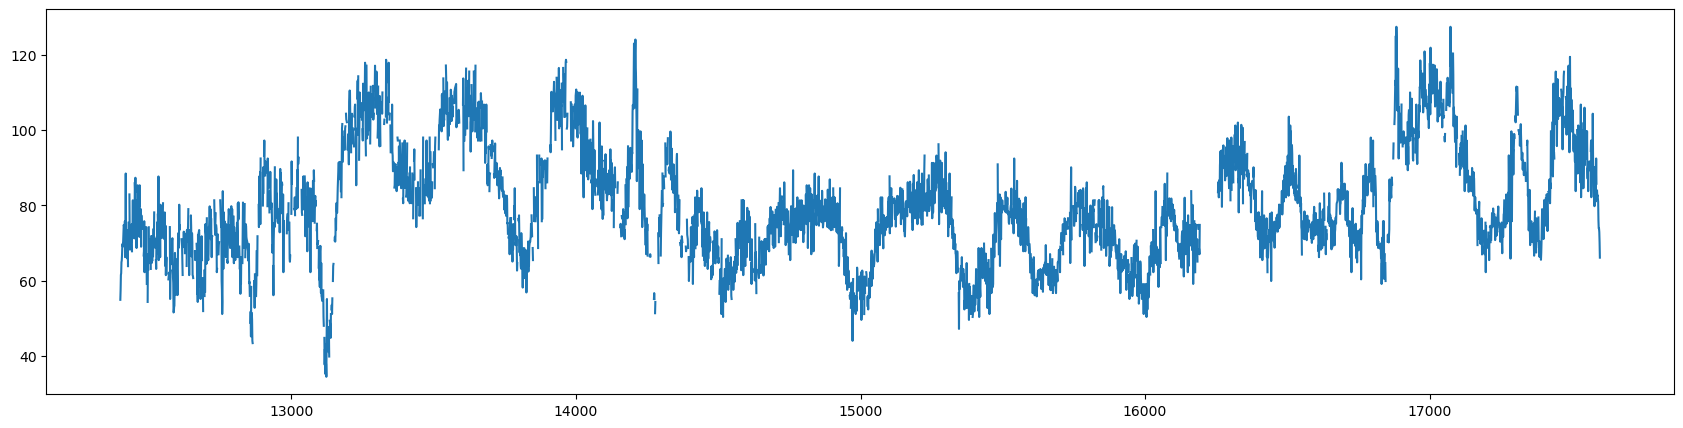

In [4]:
plt.figure(figsize=(21, 5))
plt.plot(evalz['MD'], evalz['GR'])

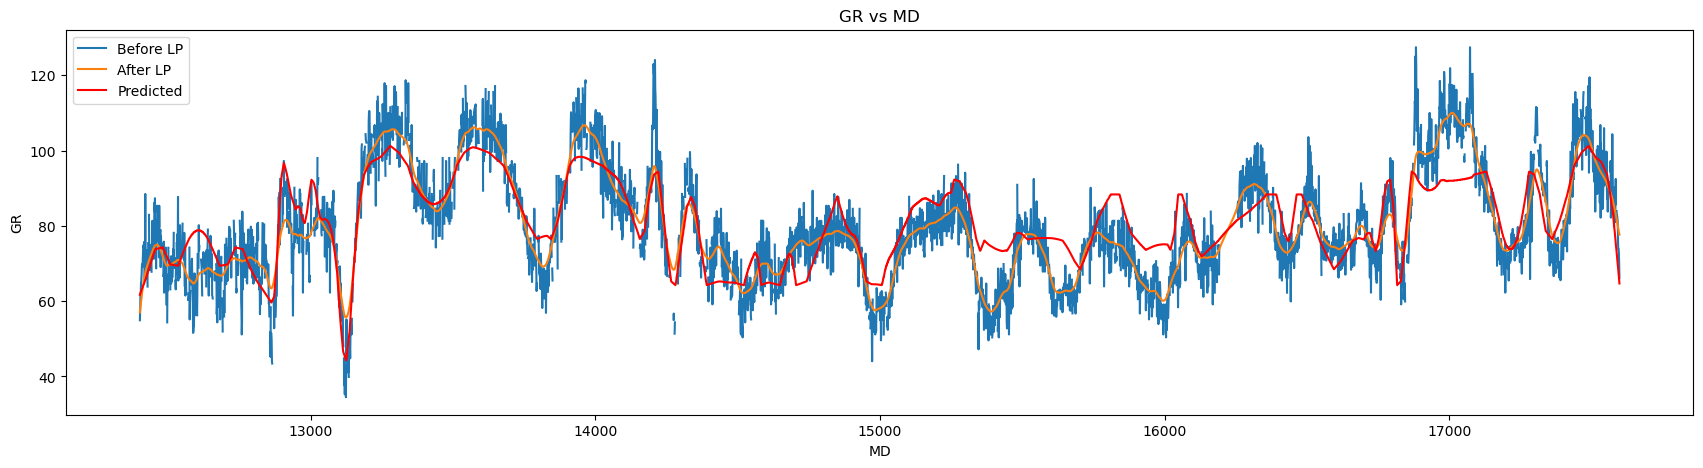

In [5]:
from scipy.signal import butter, filtfilt
from scipy.stats import pearsonr

HW_LOW_PASS_CUTOFF = 0.009
def remove_rotation_noise(gr_series, cutoff=HW_LOW_PASS_CUTOFF):
    """Low pass filter."""
    gr_filled = gr_series.interpolate(method='linear').bfill().ffill()
    nyquist = 0.5 
    normal_cutoff = cutoff / nyquist
    b, a = butter(1, normal_cutoff, btype='low', analog=False)
    return filtfilt(b, a, gr_filled)

plt.figure(figsize=(21, 5))
plt.plot(evalz['MD'], evalz['GR'], label='Before LP')
    
evalz['GR'] = remove_rotation_noise(evalz['GR'])
pred_gr = np.interp(evalz['TVT'], tw['TVT'], tw['GR'])

plt.plot(evalz['MD'], evalz['GR'], label='After LP')
plt.plot(evalz['MD'], pred_gr, label='Predicted', color='red')
plt.title('GR vs MD')
plt.xlabel('MD')
plt.ylabel('GR')
plt.legend()

In [6]:
m_z, c_z = np.polyfit(evalz['MD'], evalz['Z'], deg=1)
evalz['Z'] = evalz['Z'] - (evalz['MD'] * m_z + c_z)
evalz['Z'] = evalz['Z'] - evalz['Z'].iloc[0]

evalz['TVT'] = evalz['TVT'] - hw['TVT'].iloc[-1]

In [7]:
hw['TVT_input'].isna()

0       False
1       False
2       False
3       False
4       False
        ...  
7219     True
7220     True
7221     True
7222     True
7223     True
Name: TVT_input, Length: 7224, dtype: bool

In [8]:
len(hw[hw['TVT_input'].isna()])

5200

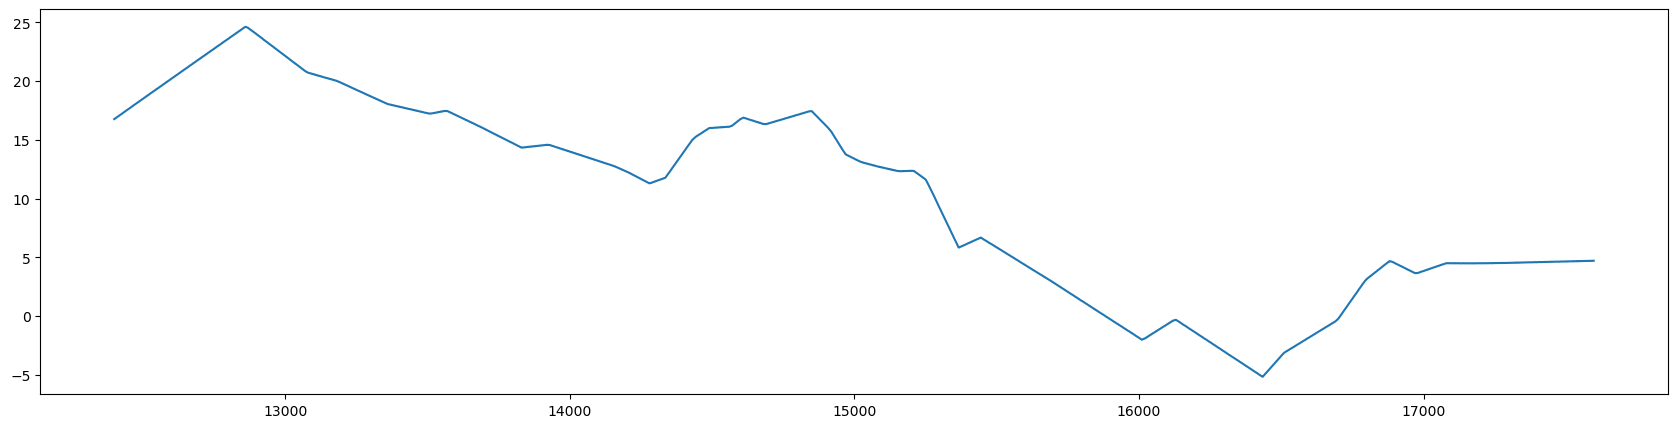

In [9]:
plt.figure(figsize=(21, 5))
label = evalz['Z'] + evalz['TVT']
plt.plot(evalz['MD'], label)

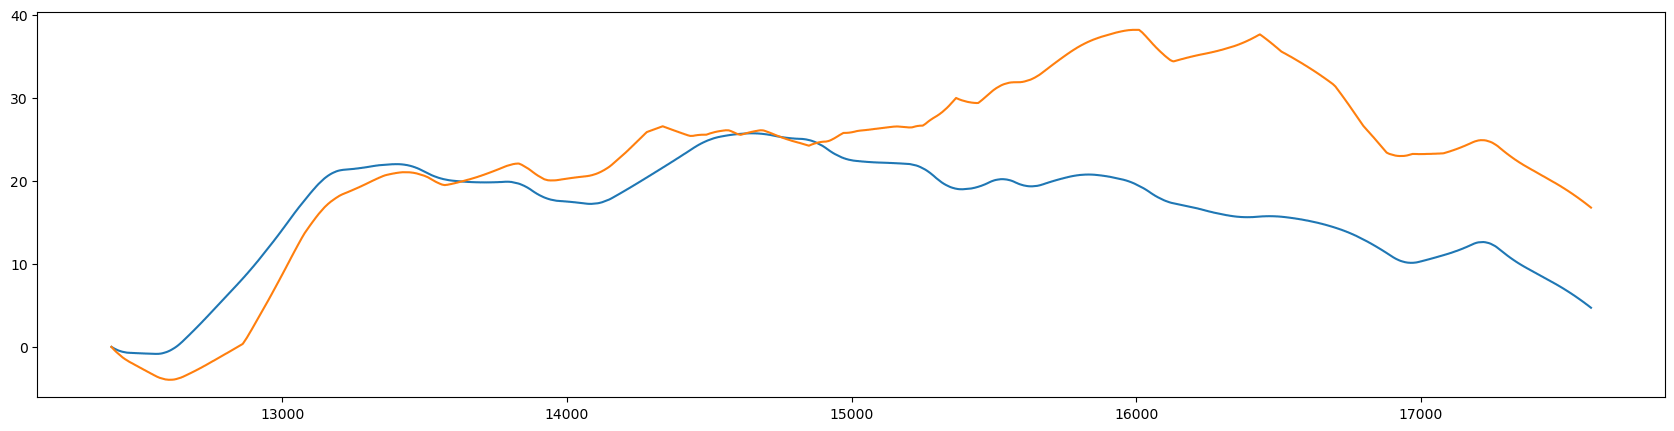

In [10]:
plt.figure(figsize=(21, 5))
plt.plot(evalz['MD'], evalz['Z'])
plt.plot(evalz['MD'], -evalz['TVT'] + evalz['TVT'].iloc[0])

In [11]:
from sklearn.metrics import root_mean_squared_error as rmse
a = rmse(evalz['TVT'], np.full(np.shape(evalz['TVT']), evalz['TVT'].iloc[0]))
b = rmse(evalz['TVT'] - evalz['TVT'].iloc[0], -evalz['Z'])
a, b

(25.39827329912237, 10.466705929458781)

### Inputs of our NN

### What does a Geologist do
* A Geologist Tries to Find Z + TVT and consequently finds TVT.
* For finding Z+TVT he matches the GR of HW, to interp GR from TW

* from hw directly
    * Z
    * TVT
    * GR
    * TVT + Z

In [12]:
import numpy as np

i = np.linspace(evalz.index[0], evalz.index[-1], 20).astype(int)
md_ = evalz['MD'][i]
tvt_ = evalz['TVT'][i]

plt.plot(md, tvt)
plt.plot(md_, tvt_)

NameError: name 'md' is not defined

In [ ]:
plt.plot(md, tvt)
plt.plot(md_, tvt_, 'o-')

In [ ]:
m2 = 0
for well in well_names:
    h = len(pd.read_csv(train_data + f"/{well}__horizontal_well.csv"))
    # e = len(h[h['TVT_input'].isna()])
    if h > m2:
        m2 = h

In [ ]:
m

In [ ]:
m2

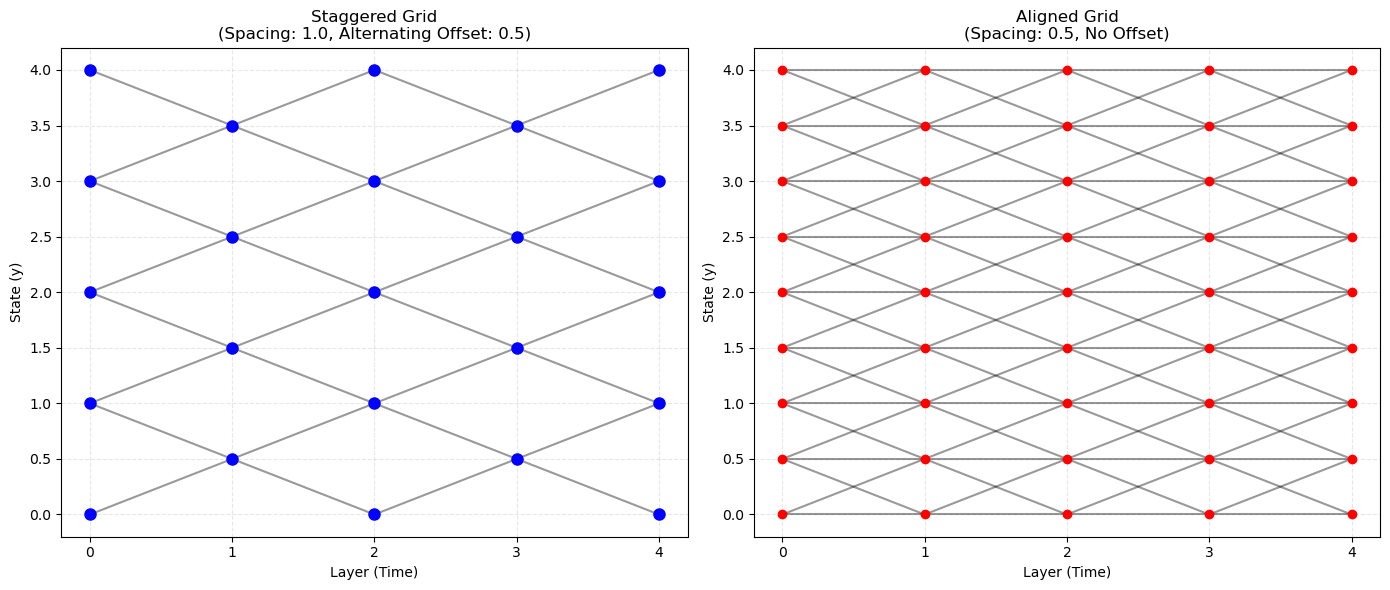

In [13]:
import matplotlib.pyplot as plt

# Setup the figure for side-by-side comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
layers = 5
max_y = 4
slope_limit = 0.51 # slightly above 0.5 to handle floating point precision

# ==========================================
# 1. Staggered Grid (Absolute Minimum Dots)
# ==========================================
ax1 = axes[0]
ax1.set_title("Staggered Grid\n(Spacing: 1.0, Alternating Offset: 0.5)")
ax1.set_xlabel("Layer (Time)")
ax1.set_ylabel("State (y)")
ax1.set_xticks(range(layers))
ax1.grid(True, linestyle='--', alpha=0.3)

staggered_dots = []
for x in range(layers):
    # Even layers get standard integers, odd layers get 0.5 offset
    if x % 2 == 0:
        y_vals = [float(y) for y in range(max_y + 1)]
    else:
        y_vals = [y + 0.5 for y in range(max_y)]
        
    for y in y_vals:
        staggered_dots.append((x, y))
        ax1.plot(x, y, 'bo', markersize=8, zorder=3) # Blue dots

# Draw paths where |m| <= 0.5
for x1, y1 in staggered_dots:
    for x2, y2 in staggered_dots:
        if x2 - x1 == 1 and abs(y2 - y1) <= slope_limit:
            ax1.plot([x1, x2], [y1, y2], 'k-', alpha=0.4, zorder=2)

# ==========================================
# 2. Aligned Grid (Standard Viterbi)
# ==========================================
ax2 = axes[1]
ax2.set_title("Aligned Grid\n(Spacing: 0.5, No Offset)")
ax2.set_xlabel("Layer (Time)")
ax2.set_ylabel("State (y)")
ax2.set_xticks(range(layers))
ax2.grid(True, linestyle='--', alpha=0.3)

aligned_dots = []
for x in range(layers):
    # Every layer has dots spaced by 0.5
    y_vals = [y * 0.5 for y in range(max_y * 2 + 1)]
    
    for y in y_vals:
        aligned_dots.append((x, y))
        ax2.plot(x, y, 'ro', markersize=6, zorder=3) # Red dots

# Draw paths where |m| <= 0.5
for x1, y1 in aligned_dots:
    for x2, y2 in aligned_dots:
        if x2 - x1 == 1 and abs(y2 - y1) <= slope_limit:
            ax2.plot([x1, x2], [y1, y2], 'k-', alpha=0.4, zorder=2)

plt.tight_layout()
plt.show()

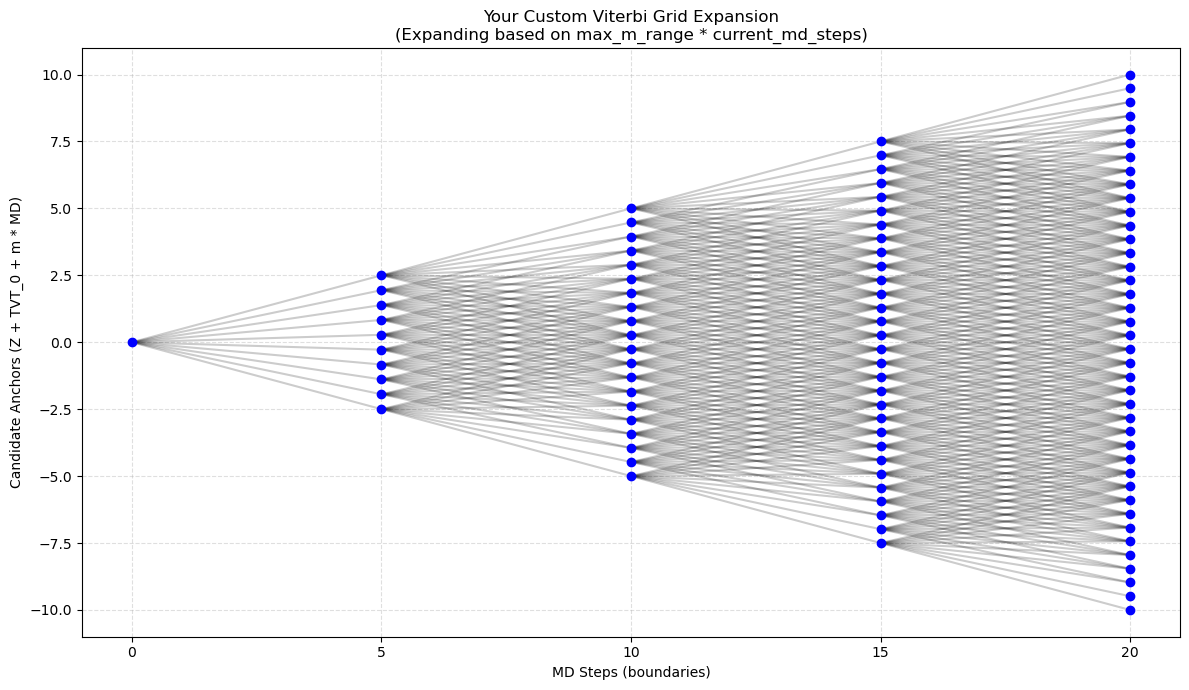

In [15]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. Mock Parameters (from your find_ms logic)
# ==========================================
boundaries = [0, 5, 10, 15, 20]  # X-axis layers (chunk boundaries)
initial_anchor = 0.0             # Equivalent to -z[0]
max_m_range = 0.5                # Dictates min/max anchor boundary expansion
max_m = 0.5                      # Max slope to connect dots (valid_mask)
anchor_density = 2.0             # How many dots per unit of Y
float_tol = 1e-5                 # Floating point tolerance

# ==========================================
# 2. Replicate Your Grid Generation
# ==========================================
anchors = [np.array([initial_anchor])]

for i in range(1, len(boundaries)):
    current_md_steps = boundaries[i]
    # Notice how your code expands based on the total steps from 0, not chunk_len
    min_anchor = initial_anchor + (-max_m_range * current_md_steps)
    max_anchor = initial_anchor + (max_m_range * current_md_steps)
    
    num_candidates = (max_anchor - min_anchor) * anchor_density
    num_candidates = max(int(num_candidates), 1)
    
    layer_anchors = np.linspace(min_anchor, max_anchor, num_candidates)
    anchors.append(layer_anchors)

# ==========================================
# 3. Plot the Grid and Valid Connections
# ==========================================
fig, ax = plt.subplots(figsize=(12, 7))
ax.set_title("Your Custom Viterbi Grid Expansion\n(Expanding based on max_m_range * current_md_steps)")
ax.set_xlabel("MD Steps (boundaries)")
ax.set_ylabel("Candidate Anchors (Z + TVT_0 + m * MD)")
ax.grid(True, linestyle='--', alpha=0.4)

# Plot the dots (anchors)
for i, b in enumerate(boundaries):
    y_vals = anchors[i]
    x_vals = [b] * len(y_vals)
    ax.plot(x_vals, y_vals, 'bo', markersize=6, zorder=3) # Blue dots

# Draw the paths matching your valid_mask logic
for i in range(len(boundaries) - 1):
    x1 = boundaries[i]
    x2 = boundaries[i+1]
    chunk_len = x2 - x1
    
    curr_anchors = anchors[i]
    next_anchors = anchors[i+1]
    
    # Replicating your M_mat logic
    for y1 in curr_anchors:
        for y2 in next_anchors:
            m = (y2 - y1) / chunk_len
            
            # Replicating: np.abs(M_mat) <= max_m
            if abs(m) <= max_m + float_tol:
                ax.plot([x1, x2], [y1, y2], 'k-', alpha=0.2, zorder=2)

# Set x-ticks exactly to your boundaries
ax.set_xticks(boundaries)
plt.tight_layout()
plt.show()

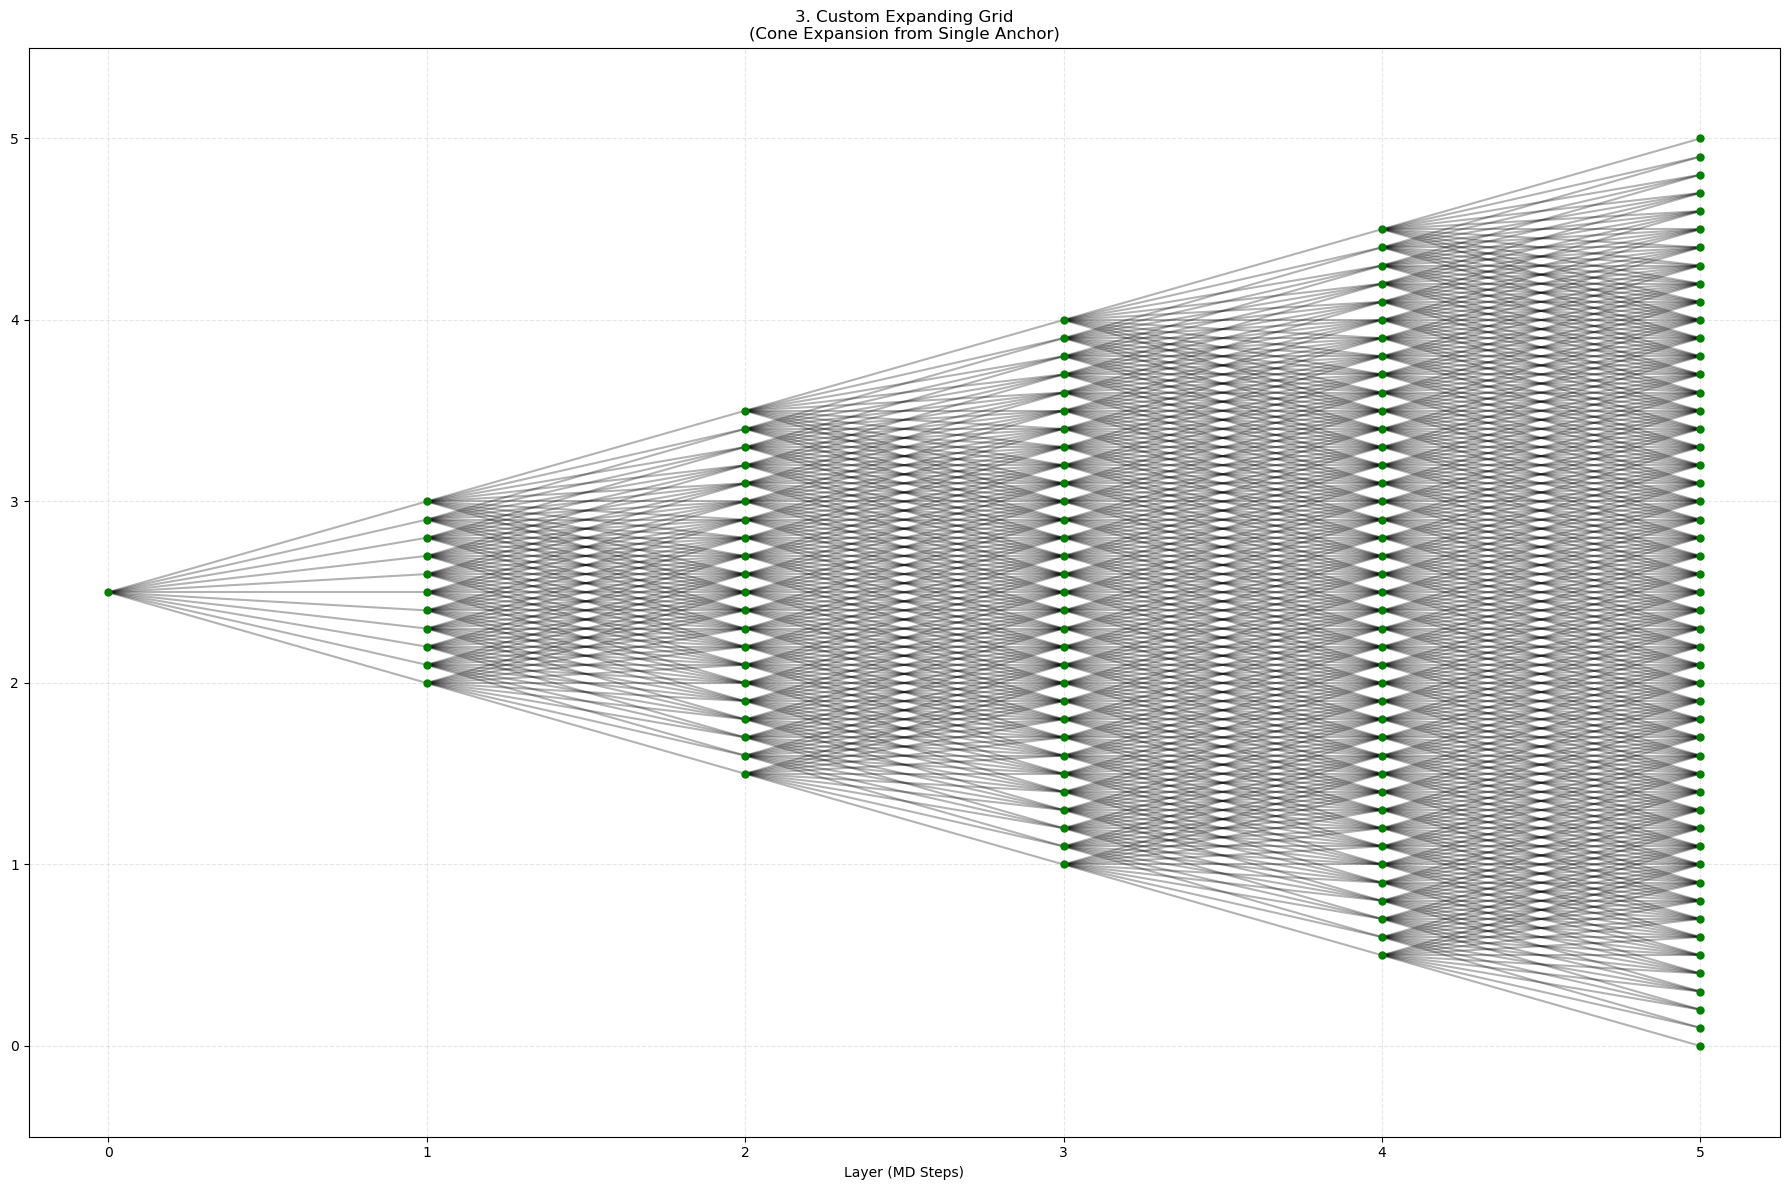

In [23]:
import matplotlib.pyplot as plt
import numpy as np

# Setup the figure for 3 side-by-side comparisons
fig, axes = plt.subplots(1, 1, figsize=(18, 12))
layers = 6
max_y = 5
slope_limit = 0.51  # Tolerance for floating point

# ==========================================
# 1. Staggered Grid (Minimal Dots, Alternating)
# ==========================================
# ax1 = axes[0]
# ax1.set_title("1. Staggered Grid\n(Spacing: 1.0, Offset: 0.5, Uniform Width)")
# ax1.set_xlabel("Layer (Time)")
# ax1.set_ylabel("State (y)")
# ax1.set_xticks(range(layers))
# ax1.grid(True, linestyle='--', alpha=0.3)
# ax1.set_ylim(-0.5, max_y + 0.5)

# staggered_dots = []
# for x in range(layers):
#     if x % 2 == 0:
#         y_vals = [float(y) for y in range(max_y + 1)]
#     else:
#         y_vals = [y + 0.5 for y in range(max_y)]
        
#     for y in y_vals:
#         staggered_dots.append((x, y))
#         ax1.plot(x, y, 'bo', markersize=6, zorder=3)

# for x1, y1 in staggered_dots:
#     for x2, y2 in staggered_dots:
#         if x2 - x1 == 1 and abs(y2 - y1) <= slope_limit:
#             ax1.plot([x1, x2], [y1, y2], 'k-', alpha=0.3, zorder=2)

# # ==========================================
# # 2. Aligned Grid (Standard Viterbi)
# # ==========================================
# ax2 = axes[1]
# ax2.set_title("2. Aligned Grid\n(Spacing: 0.5, No Offset, Uniform Width)")
# ax2.set_xlabel("Layer (Time)")
# ax2.set_xticks(range(layers))
# ax2.grid(True, linestyle='--', alpha=0.3)
# ax2.set_ylim(-0.5, max_y + 0.5)

# aligned_dots = []
# for x in range(layers):
#     y_vals = [y * 0.5 for y in range(max_y * 2 + 1)]
#     for y in y_vals:
#         aligned_dots.append((x, y))
#         ax2.plot(x, y, 'ro', markersize=5, zorder=3)

# for x1, y1 in aligned_dots:
#     for x2, y2 in aligned_dots:
#         if x2 - x1 == 1 and abs(y2 - y1) <= slope_limit:
#             ax2.plot([x1, x2], [y1, y2], 'k-', alpha=0.3, zorder=2)

# ==========================================
# 3. Custom Expanding Grid (Your Code's Logic)
# ==========================================
ax3 = axes
ax3.set_title("3. Custom Expanding Grid\n(Cone Expansion from Single Anchor)")
ax3.set_xlabel("Layer (MD Steps)")
ax3.set_xticks(range(layers))
ax3.grid(True, linestyle='--', alpha=0.3)
ax3.set_ylim(-0.5, max_y + 0.5)

custom_dots = []
anchors = []
initial_y = 2.5  # Centered starting point
anchor_density = 10.0  # Equivalent to 0.5 spacing

for x in range(layers):
    if x == 0:
        y_vals = [initial_y]
    else:
        # Expanding boundaries based on current layer (x)
        min_y = initial_y - (0.5 * x)
        max_y_val = initial_y + (0.5 * x)
        
        # Calculate number of candidates like your find_ms function
        num_candidates = (max_y_val - min_y) * anchor_density
        num_candidates = max(int(num_candidates) + 1, 1)
        
        y_vals = np.linspace(min_y, max_y_val, num_candidates)
    
    anchors.append(y_vals)
    for y in y_vals:
        custom_dots.append((x, y))
        ax3.plot(x, y, 'go', markersize=5, zorder=3) # Green dots

for x in range(layers - 1):
    curr_anchors = anchors[x]
    next_anchors = anchors[x+1]
    
    for y1 in curr_anchors:
        for y2 in next_anchors:
            # m = (y2 - y1) / chunk_len (where chunk_len is 1 here)
            if abs(y2 - y1) <= slope_limit:
                ax3.plot([x, x + 1], [y1, y2], 'k-', alpha=0.3, zorder=2)

plt.tight_layout()
plt.show()

* Converting the whole custom viterbi into a repeatable pattern for batching
* Getting a probability distribution